# Step 1 — Exploratory Data Analysis (EDA)
**Dataset:** UCI Heart Disease — all four hospital sources (Cleveland, Hungary, Switzerland, VA Long Beach)
**Task:** binary classification (heart disease yes/no)

**Goal of this notebook:** understand the data *before* modelling — its size, quality problems, class balance,
how the four hospitals differ, and which features carry signal — and record decisions for Step 2.

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Find the project root whether the notebook runs from the root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "source_data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "source_data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Chart styling: one fixed colour per class, used in every chart
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}          # blue = no disease, orange = disease
CLASS_NAMES = {0: "No disease", 1: "Disease"}
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"])

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "grid.color": "#ebeae6", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "figure.dpi": 110,
})

def save(fig, name):
    """Save every chart to reports/figures/ for the final report."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

Matplotlib is building the font cache; this may take a moment.


## 2. Load all four sources into one DataFrame
Each file is checked before it is combined:
1. **File exists** — a typo in a name fails instead of loading fewer files.
2. **Column count = 14** — catches the wrong file.
3. **All columns numeric** — catches a different separator or missing-value marker.

A `source` column records which hospital each row came from.

In [2]:
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

SOURCES = {
    "cleveland":   "processed.cleveland.data",
    "hungary":     "processed.hungarian.data",
    "switzerland": "processed.switzerland.data",
    "va":          "processed.va.data",
}

frames = []
for source, filename in SOURCES.items():
    path = DATA_DIR / filename
    assert path.exists(), f"Missing file: {path}"

    raw = pd.read_csv(path, header=None, na_values="?")
    assert raw.shape[1] == len(COLUMNS), (
        f"{filename}: expected {len(COLUMNS)} columns, found {raw.shape[1]}")
    raw.columns = COLUMNS

    non_numeric = [c for c in COLUMNS if not pd.api.types.is_numeric_dtype(raw[c])]
    assert not non_numeric, f"{filename}: non-numeric columns {non_numeric}"

    raw["source"] = source
    frames.append(raw)
    print(f"{source:<12} {len(raw):>4} rows  OK")

df = pd.concat(frames, ignore_index=True)
df["target"] = (df["num"] > 0).astype(int)     # 0 = no disease, 1 = disease (any of 1-4)
df = df.drop(columns="num")
print(f"\nCombined: {df.shape[0]} rows x {df.shape[1]} columns")

cleveland     303 rows  OK
hungary       294 rows  OK
switzerland   123 rows  OK
va            200 rows  OK

Combined: 920 rows x 15 columns


### Hidden missing values: zeros that mean "unknown"
Some hospitals recorded unknown cholesterol (and at least one blood pressure) as **0** instead of `?`.
A value of 0 is physiologically impossible, so it is treated as missing. Otherwise a model would learn that
"cholesterol = 0" means something, when it is only a recording artifact.

In [3]:
zero_counts = (df[["chol", "trestbps"]] == 0).groupby(df["source"]).sum()
print("Zeros found (rows per source):")
print(zero_counts.to_string())

df[["chol", "trestbps"]] = df[["chol", "trestbps"]].replace(0, np.nan)
df.head()

Zeros found (rows per source):
             chol  trestbps
source                     
cleveland       0         0
hungary         0         0
switzerland   123         0
va             49         1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,source,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,cleveland,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,cleveland,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,cleveland,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,cleveland,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,cleveland,0


### Feature dictionary
The numbers in several columns are **codes for categories**, not quantities. A model that treats `cp = 4` as "twice" `cp = 2` would be wrong, so we must label each column's type correctly.

| Column | Meaning | Type | Values |
|---|---|---|---|
| age | Age | numeric | years |
| sex | Sex | binary | 1 = male, 0 = female |
| cp | Chest pain type | categorical | 1 typical angina, 2 atypical angina, 3 non-anginal, 4 asymptomatic |
| trestbps | Resting blood pressure | numeric | mm Hg |
| chol | Serum cholesterol | numeric | mg/dl |
| fbs | Fasting blood sugar > 120 mg/dl | binary | 1 = true |
| restecg | Resting ECG result | categorical | 0 normal, 1 ST-T abnormality, 2 LV hypertrophy |
| thalach | Max heart rate achieved | numeric | bpm |
| exang | Exercise-induced angina | binary | 1 = yes |
| oldpeak | ST depression (exercise vs rest) | numeric | mm |
| slope | Slope of peak exercise ST segment | categorical | 1 up, 2 flat, 3 down |
| ca | Major vessels coloured by fluoroscopy | ordinal | 0–3 |
| thal | Thallium stress test | categorical | 3 normal, 6 fixed defect, 7 reversible defect |
| source | Hospital the record came from | label | cleveland, hungary, switzerland, va — **analysis only, not a model feature** |
| **target** | Heart disease | binary | 0 = no, 1 = yes (from original `num` 0–4) |

In [4]:
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "target"

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       920 non-null    float64
 1   sex       920 non-null    float64
 2   cp        920 non-null    float64
 3   trestbps  860 non-null    float64
 4   chol      718 non-null    float64
 5   fbs       830 non-null    float64
 6   restecg   918 non-null    float64
 7   thalach   865 non-null    float64
 8   exang     865 non-null    float64
 9   oldpeak   858 non-null    float64
 10  slope     611 non-null    float64
 11  ca        309 non-null    float64
 12  thal      434 non-null    float64
 13  source    920 non-null    str    
 14  target    920 non-null    int64  
dtypes: float64(13), int64(1), str(1)
memory usage: 107.9 KB


## 3. Summary statistics (numeric features)

In [5]:
df[NUMERIC].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
age,920.0,53.5,9.4,28.0,47.0,54.0,60.0,77.0
trestbps,860.0,132.3,18.5,80.0,120.0,130.0,140.0,200.0
chol,718.0,246.8,58.5,85.0,210.0,239.5,276.8,603.0
thalach,865.0,137.5,25.9,60.0,120.0,140.0,157.0,202.0
oldpeak,858.0,0.9,1.1,-2.6,0.0,0.5,1.5,6.2


## 4. Comparing the four sources
The hospitals collected data differently and saw different patients. Before treating them as one dataset,
check how much they differ in size, disease rate and completeness.

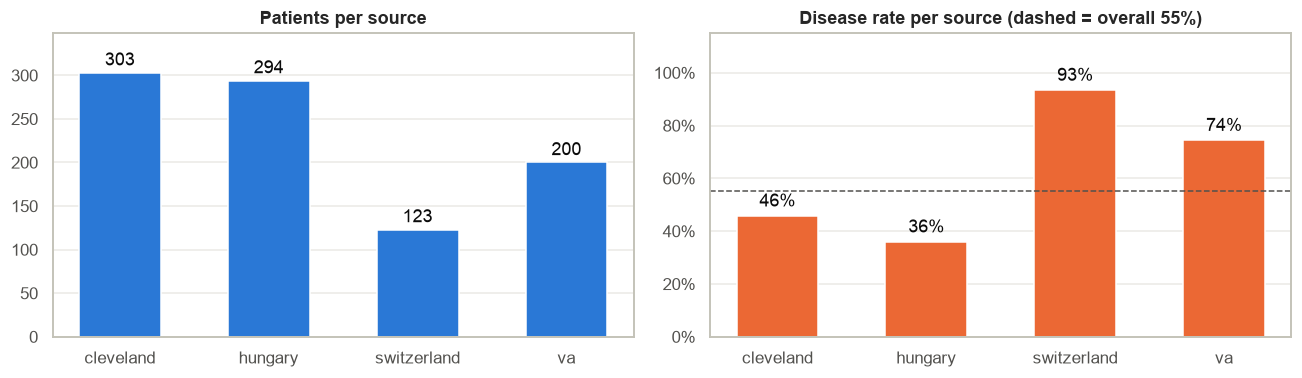

,rows,disease_rate
source,,
cleveland,303,0.46
hungary,294,0.36
switzerland,123,0.93
va,200,0.74


In [6]:
by_source = df.groupby("source")[TARGET].agg(rows="size", disease_rate="mean")
by_source = by_source.loc[list(SOURCES)]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(by_source.index, by_source["rows"], color="#2a78d6", width=0.55)
for x, n in enumerate(by_source["rows"]):
    axes[0].text(x, n + 4, str(n), ha="center", va="bottom", color="#0b0b0b")
axes[0].set_title("Patients per source")
axes[0].set_ylim(0, by_source["rows"].max() * 1.15)

overall = df[TARGET].mean()
axes[1].bar(by_source.index, by_source["disease_rate"], color="#eb6834", width=0.55)
axes[1].axhline(overall, color="#52514e", linestyle="--", linewidth=1)
for x, r in enumerate(by_source["disease_rate"]):
    axes[1].text(x, r + 0.02, f"{r:.0%}", ha="center", va="bottom", color="#0b0b0b")
axes[1].set_title(f"Disease rate per source (dashed = overall {overall:.0%})")
axes[1].set_ylim(0, 1.15)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in axes:
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "01_rows_and_disease_rate_by_source")
plt.show()

by_source.round(2)

## 5. Data quality: missing values and duplicates
With four sources, missingness is the biggest data-quality question. The heatmap shows the **% of values missing per column, per hospital**.

In [7]:
missing = df[FEATURES].isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(1)
print("Duplicate rows:", df.duplicated().sum())
missing.sort_values("missing_pct", ascending=False)

Duplicate rows: 2


,missing_count,missing_pct
ca,611,66.4
thal,486,52.8
slope,309,33.6
chol,202,22.0
fbs,90,9.8
oldpeak,62,6.7
trestbps,60,6.5
thalach,55,6.0
exang,55,6.0
restecg,2,0.2


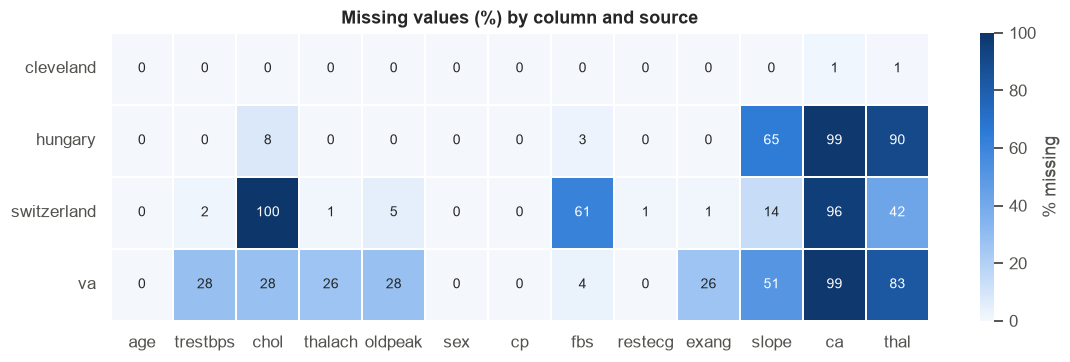

In [8]:
miss_by_source = df[FEATURES].isna().groupby(df["source"]).mean().mul(100).loc[list(SOURCES)]

fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(miss_by_source, cmap=SEQUENTIAL, vmin=0, vmax=100, annot=True, fmt=".0f",
            annot_kws={"size": 9}, linewidths=1, linecolor="white",
            cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values (%) by column and source")
ax.set_xlabel("")
ax.set_ylabel("")
save(fig, "02_missing_by_source")
plt.show()

## 6. Target distribution (class balance)
If one class heavily outnumbers the other, accuracy becomes misleading and we need special handling.

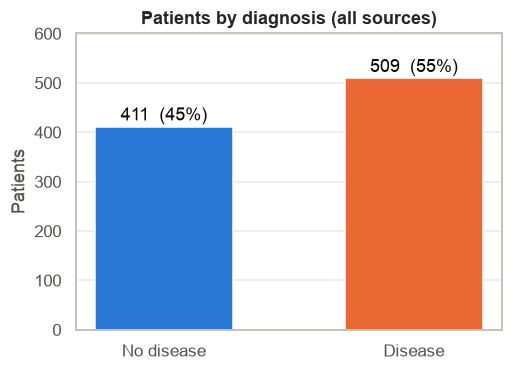

In [9]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar([CLASS_NAMES[i] for i in counts.index], counts.values,
              color=[CLASS_COLORS[i] for i in counts.index], width=0.55)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 5, f"{n}  ({n / len(df):.0%})",
            ha="center", va="bottom", color="#0b0b0b")
ax.set_title("Patients by diagnosis (all sources)")
ax.set_ylabel("Patients")
ax.set_ylim(0, counts.max() * 1.18)
ax.grid(axis="x", visible=False)
save(fig, "03_target_balance")
plt.show()

## 7. Numeric features: how do they differ between classes
Overlapping distributions = weak signal. Clearly shifted distributions = useful feature.
(Missing values are left out of each curve.)

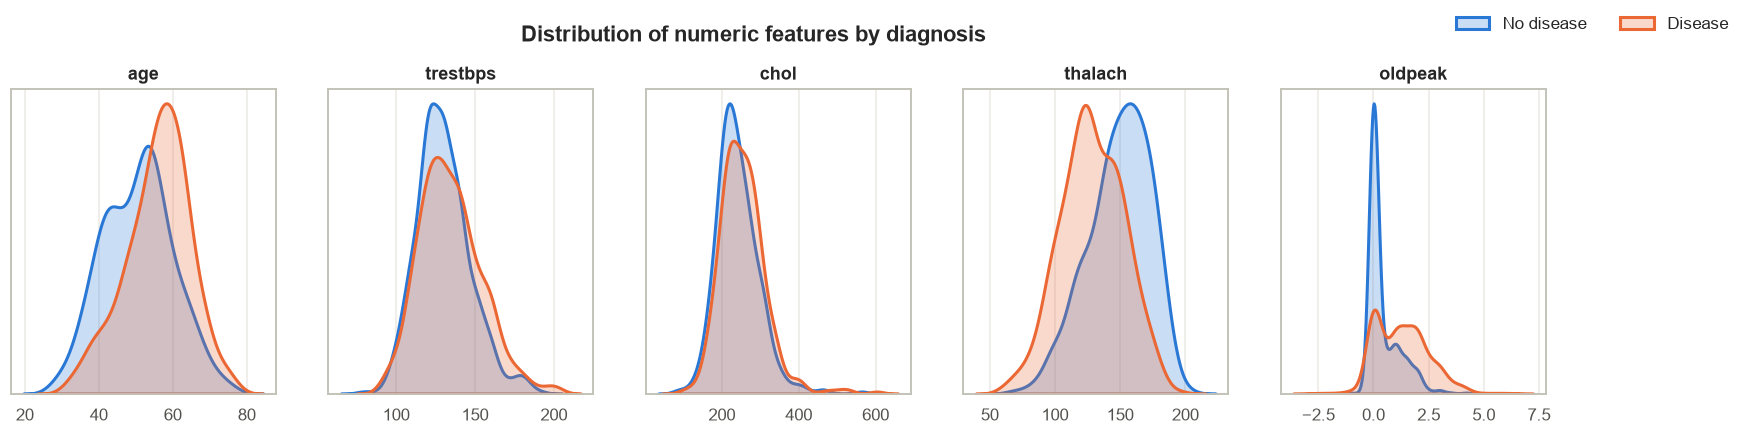

,age,trestbps,chol,thalach,oldpeak
target,,,,,
No disease,51.0,130.0,233.0,151.0,0.0
Disease,57.0,130.0,248.0,128.0,1.0


In [10]:
fig, axes = plt.subplots(1, len(NUMERIC), figsize=(18, 3.6))
for ax, col in zip(axes, NUMERIC):
    for cls in (0, 1):
        sns.kdeplot(df.loc[df[TARGET] == cls, col].dropna(), ax=ax, fill=True, alpha=0.25,
                    color=CLASS_COLORS[cls], linewidth=2, label=CLASS_NAMES[cls])
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, bbox_to_anchor=(1, 1.1))
fig.suptitle("Distribution of numeric features by diagnosis", y=1.04, fontweight="bold")
save(fig, "04_numeric_by_target")
plt.show()

# Same comparison as numbers: median per class
df.groupby(TARGET)[NUMERIC].median().rename(index=CLASS_NAMES).round(1)

## 8. Categorical features: disease rate per category
For each category, what share of patients have heart disease? Bars far from the overall rate (dashed line) indicate a strong feature.
Missing values are excluded here — check `n` to see how much data stands behind each bar.

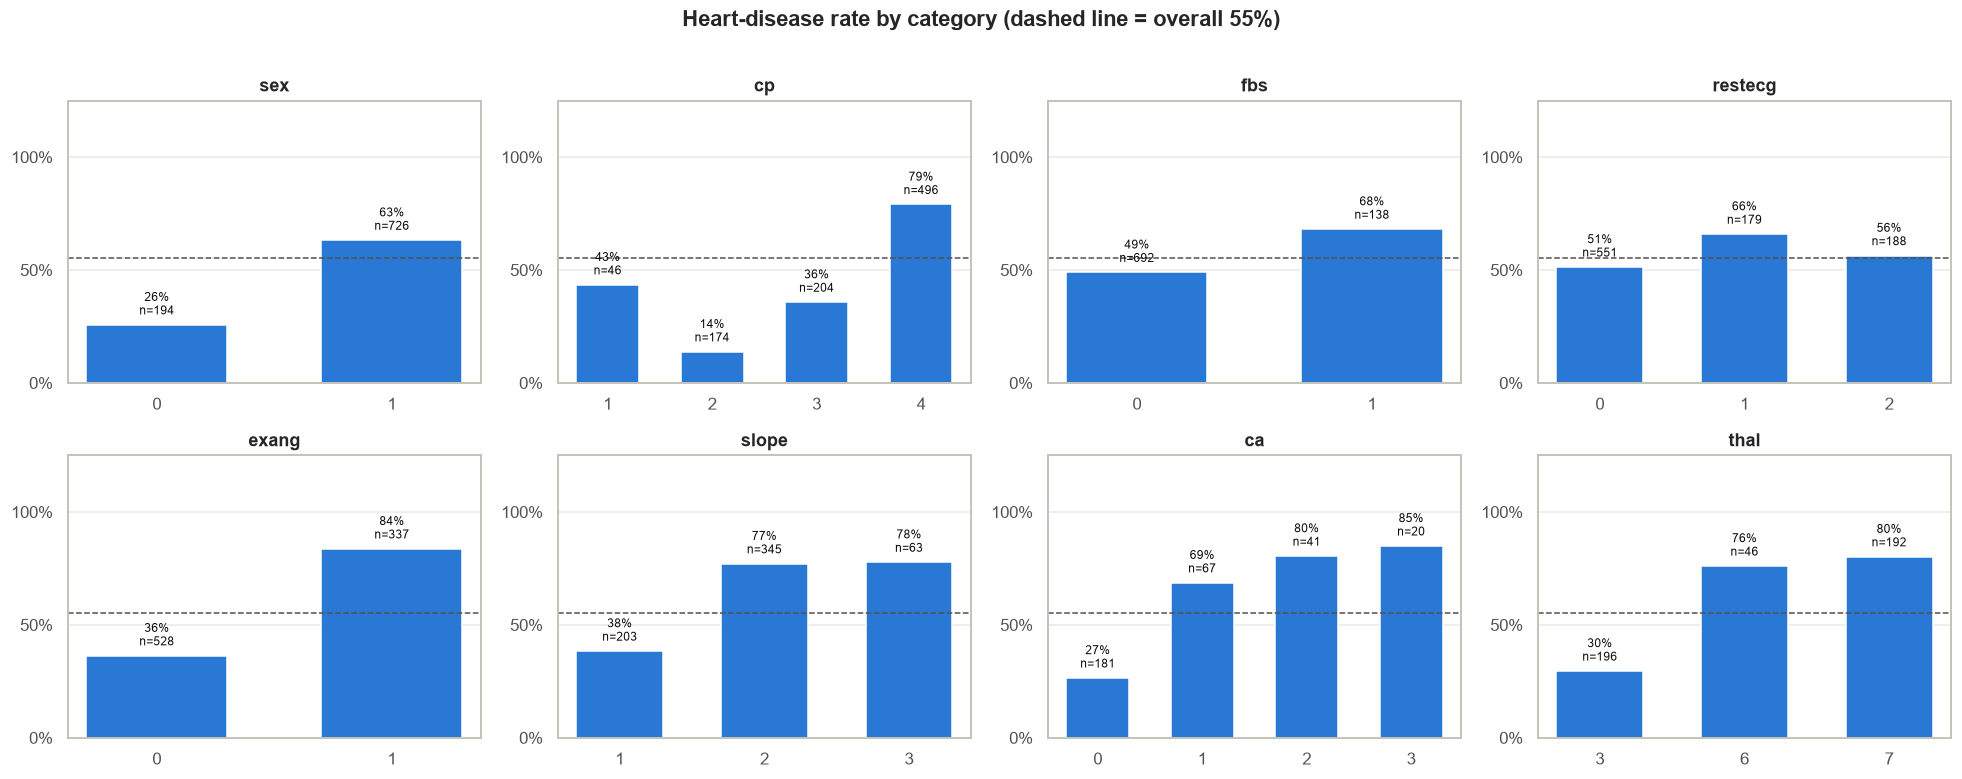

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), CATEGORICAL):
    stats = df.groupby(col)[TARGET].agg(["mean", "size"])
    ax.bar(stats.index.astype(int).astype(str), stats["mean"], color="#2a78d6", width=0.6)
    ax.axhline(overall, color="#52514e", linestyle="--", linewidth=1)
    for x, (rate, n) in enumerate(zip(stats["mean"], stats["size"])):
        ax.text(x, rate + 0.03, f"{rate:.0%}\nn={n}", ha="center", va="bottom",
                fontsize=8, color="#0b0b0b")
    ax.set_title(col)
    ax.set_ylim(0, 1.25)
    ax.set_yticks([0, 0.5, 1])
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Heart-disease rate by category (dashed line = overall {overall:.0%})",
             y=1.01, fontweight="bold")
fig.tight_layout()
save(fig, "05_categorical_disease_rate")
plt.show()

## 9. Correlations
Shows linear relationships between features and with the target. Watch for (a) features strongly linked to `target` and (b) pairs of features strongly linked to *each other* (redundancy).

*Caveats:* Pearson correlation on category codes like `cp` or `thal` is only a rough guide — section 8 is the better view for those.
Correlations use only rows where both values exist, so heavily-missing columns (`ca`, `thal`, `slope`) rest on far fewer patients.

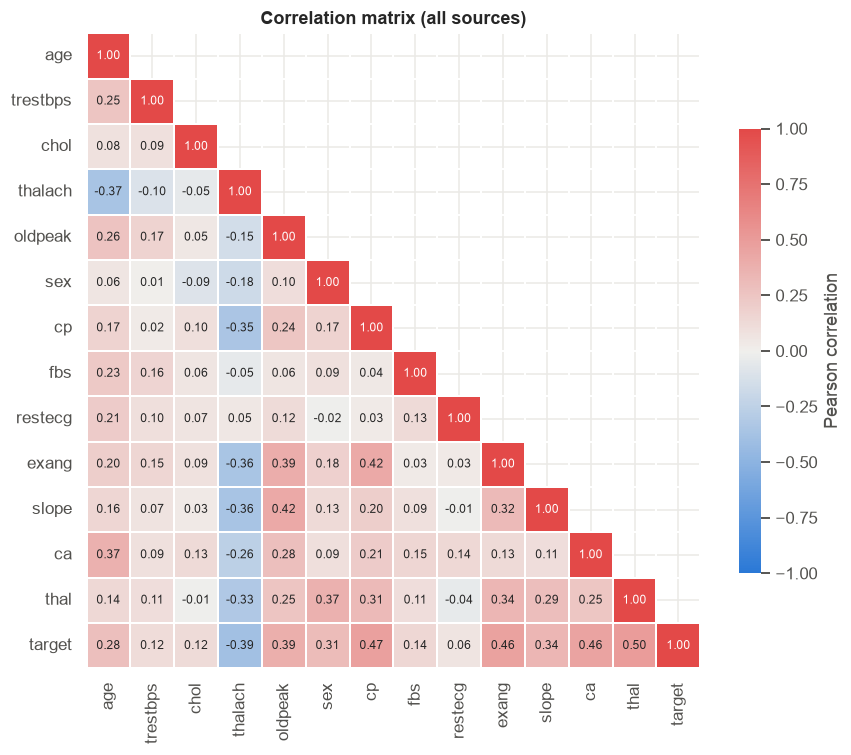

In [12]:
corr = df[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True,
            fmt=".2f", annot_kws={"size": 8}, linewidths=1, linecolor="white",
            cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation matrix (all sources)")
save(fig, "06_correlation_matrix")
plt.show()

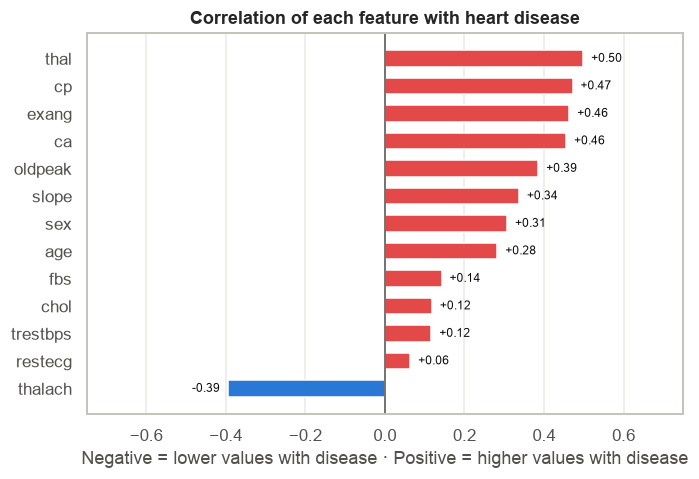

In [13]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(target_corr.index, target_corr.values,
        color=["#2a78d6" if v < 0 else "#e34948" for v in target_corr.values], height=0.6)
ax.axvline(0, color="#52514e", linewidth=1)
for y, v in enumerate(target_corr.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), y, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color="#0b0b0b")
ax.set_xlim(-0.75, 0.75)
ax.set_title("Correlation of each feature with heart disease")
ax.set_xlabel("Negative = lower values with disease · Positive = higher values with disease")
ax.grid(axis="y", visible=False)
save(fig, "07_correlation_with_target")
plt.show()

## 10. Outliers
Boxplots plus a simple IQR rule (points beyond 1.5 × IQR from the box). An outlier is a question, not a verdict — check whether the value is medically plausible before deciding anything.

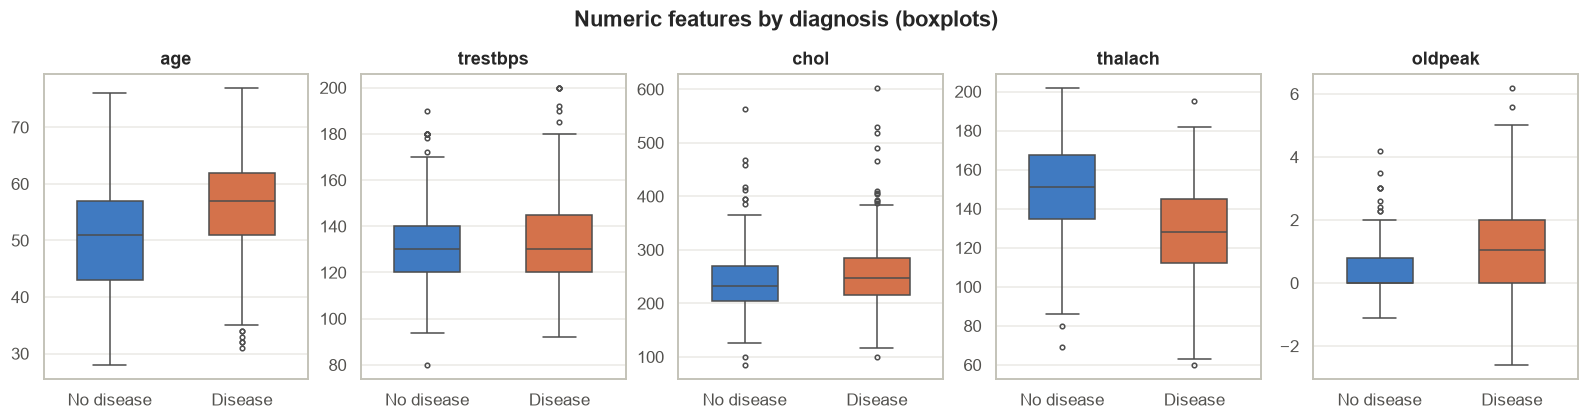

,outliers,min,max
age,0,28.0,77.0
trestbps,27,80.0,200.0
chol,23,85.0,603.0
thalach,2,60.0,202.0
oldpeak,16,-2.6,6.2


In [14]:
fig, axes = plt.subplots(1, len(NUMERIC), figsize=(18, 3.6))
for ax, col in zip(axes, NUMERIC):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, ax=ax, legend=False, width=0.5,
                palette=CLASS_COLORS, fliersize=3)
    ax.set_xticks([0, 1], [CLASS_NAMES[0], CLASS_NAMES[1]])
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Numeric features by diagnosis (boxplots)", y=1.04, fontweight="bold")
save(fig, "08_outliers_boxplots")
plt.show()

def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({
    "outliers": {c: iqr_outliers(df[c]) for c in NUMERIC},
    "min": df[NUMERIC].min(), "max": df[NUMERIC].max(),
})

## 11. Key findings
*Fill this in from **your** outputs above. The prompts tell you what to look for; don't copy them as findings.*

**Data size & sources**
- Rows per source and combined total: …
- How different are the disease rates across sources? Which source stands out? …

**Data quality**
- Hidden zeros found (`chol`, `trestbps`) and in which sources: …
- Columns with heavy missingness, and which sources cause it: …
- Duplicates: …

**Class balance**
- Overall split between classes: … → balanced enough for standard training? …

**Strongest signals** (sections 7–9)
- Numeric: which features shift most between classes? (check `thalach`, `oldpeak`, `age`) …
- Categorical: which categories have disease rates far from the overall rate? (check `cp`, `exang`, `sex`, `ca`, `thal`) …
- Weak or no signal: … (check `chol`, `fbs`)

**Outliers**
- Which features, which values, are they plausible? …

---
## 12. Decisions carried into Step 2
These follow from the EDA and will be implemented in the model pipeline:

1. **Use all four sources (~920 rows)** — more data, more realistic variety. Keep `source` for analysis and splitting, but **never as a model feature**: a new patient in production doesn't come "from Cleveland 1988".
2. **Hidden zeros** in `chol` and `trestbps` → already converted to missing in this notebook; the same rule must be applied in the training code and at the API boundary.
3. **Heavily missing columns** (`ca`, `thal`, `slope`) → compare two options in Step 2 using cross-validation:
   (a) drop these columns, or (b) impute them and add "was missing" indicator columns. Pick whichever scores better.
4. **Other missing values** → impute **inside** the sklearn Pipeline (median for numeric, most-frequent for categorical), never by editing the data files — so training and the production API handle them identically.
5. **Categorical features** (`cp`, `restecg`, `slope`, `thal`) → one-hot encode; never treat their codes as quantities. **Numeric features** → standardise.
6. **Outliers** → keep plausible values (e.g. high cholesterol is real); no row deletion.
7. **Splitting** → stratified 5-fold cross-validation, stratified on **target and source together**, so every fold contains each hospital in its true proportion. Report mean ± std.
8. **Metric** → prioritise **recall** and **ROC-AUC**: missing a sick patient costs more than a false alarm.